# 03 · Uplift models: T-learner (main), X-learner, S-learner, and an honest uplift tree

**Question each model answers:** *for this customer, how much does each email change the probability of a visit?*
That number is the **estimated uplift score**: a model estimate, not an observed effect and not a probability.

* **T-learner (main model, fixed in advance):** one visit model per arm (control, men's, women's). Uplift = P(visit | email) − P(visit | no email).
* **X-learner:** starts from the same three models, then models the *effect itself* in a second stage.
* **S-learner:** one model with the arm as a feature (simple comparison).
* **Honest uplift tree (new, interpretable):** splits customers directly where the uplift differs, with three guards against noise (honest estimation, large leaves, significant splits only). Its output is a short list of plain-language rules.

**Two ways to choose settings.** The meta-learners are tuned by the log-loss of their outcome models (good probabilities). But a good outcome model is not automatically a good *uplift ranker*, because uplift is a small difference between two noisy predictions. So section 4 adds an **uplift-aware** comparison: 5-fold cross-fitted Qini on the training set, the metric we actually care about. Everything in this notebook uses the training set only; the test set is scored at the end and evaluated in notebook 04.

In [1]:
# Make `src` importable from the notebooks folder (works on Windows and macOS)
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import *
FIG_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_json(obj, name):
    (RESULTS_DIR / name).write_text(json.dumps(obj, indent=2, default=float))

In [2]:
import joblib
from sklearn.model_selection import StratifiedKFold
from src.preprocessing import make_split, fit_transform_features
from src.models import TLearner, XLearner, SLearner, UpliftTreeLearner, PropensityModel, base_classifier, recommend, model_inferred_segment
from src.crossfit import cross_fit_uplift, cross_fit_single, qini_per_email, select_tree_params
from src.evaluation import qini_coefficient, uplift_by_decile, diff_in_means

train, validation, test = make_split()

X_tr, X_val, X_te, pre = fit_transform_features(
    train, validation, test
)

y_tr = train["visit"].to_numpy()
a_tr = train["arm"].to_numpy()

print("Training:", X_tr.shape)
print("Validation:", X_val.shape)
print("Testing:", X_te.shape)

Training: (38400, 11)
Validation: (12800, 11)
Testing: (12800, 11)


## 1. T-learner with light tuning
For each arm separately, a 3-fold cross-validated grid search (8 combinations of learning rate, tree size and minimum leaf size) picks the parameters with the best log-loss. We use log-loss rather than accuracy because uplift is a **difference of two probabilities**, so the probabilities themselves must be well calibrated.

In [3]:
t_learner = TLearner().fit(X_tr, y_tr, a_tr, tune=True)
for a, p in t_learner.params_.items():
    print(f"{ARMS[a]:14s} -> {p}")

No E-Mail      -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}
Mens E-Mail    -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
Womens E-Mail  -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}


## 2. X-learner and S-learner
The X-learner reuses the tuned T-learner as its first stage. The S-learner uses the parameters tuned for the control model (a reasonable middle choice; it is only a comparison).

In [4]:
x_learner = XLearner(stage1=t_learner).fit(X_tr, y_tr, a_tr)
s_learner = SLearner(params=t_learner.params_[0]).fit(X_tr, y_tr, a_tr)
print("X-learner blend weights g (share of email arm):", {ARMS[a]: round(g, 3) for a, g in x_learner.g_.items()})

X-learner blend weights g (share of email arm): {'Mens E-Mail': np.float64(0.5), 'Womens E-Mail': np.float64(0.501)}


## 3. Honest uplift tree, tuned on the metric that matters
A tree that splits where the **uplift** (treated − control visit rate) differs most between the two sides, one tree per email. Three guards against noise, the main danger in uplift modeling:
1. **Honesty** (Athey & Imbens): one random half of the training data chooses the splits, the *other* half estimates each leaf's uplift.
2. **Large leaves**: at least `min_leaf` customers per leaf.
3. **Significance gate**: a split is kept only if the two sides' uplifts differ by at least `min_t` standard errors (`min_t = 0` switches the gate off, giving a classic uplift tree).

Settings are chosen per email with **uplift-aware tuning**: for each candidate setting, 5-fold cross-fitted scores on train and the Qini coefficient they achieve; then the **one-standard-error rule** (as in CART pruning) takes the simplest setting whose Qini is within one bootstrap standard error of the best. Hand-written in `src/models.py` (about 80 lines).

,max_depth,min_leaf,min_t,qini_mens,qini_womens,within_1se_mens,chosen_mens,within_1se_womens,chosen_womens
0,2,500,0.000000,-0.0005,0.0032,True,False,True,False
1,2,500,2.000000,-0.0004,0.0036,True,False,True,False
2,2,1000,0.000000,-0.0003,0.0031,True,False,True,False
3,2,1000,2.000000,-0.0003,0.0036,True,True,True,True
4,3,500,0.000000,-0.0007,0.0028,True,False,False,False
5,3,500,2.000000,-0.0004,0.0035,True,False,True,False
6,3,1000,0.000000,-0.0004,0.0030,True,False,True,False
7,3,1000,2.000000,-0.0003,0.0036,True,False,True,False


Chosen per email: {'Mens E-Mail': {'max_depth': 2, 'min_leaf': 1000, 'min_t': 2}, 'Womens E-Mail': {'max_depth': 2, 'min_leaf': 1000, 'min_t': 2}}

Mens E-Mail: rules learned (uplift in visit points, n = customers in the estimation half)


,rule,uplift,n
0,zip_code_Rural = yes,9.4000,1869
1,zip_code_Rural = no,8.1000,10915



Womens E-Mail: rules learned (uplift in visit points, n = customers in the estimation half)


,rule,uplift,n
0,womens = yes,7.4000,7140
1,womens = no,1.2000,5668


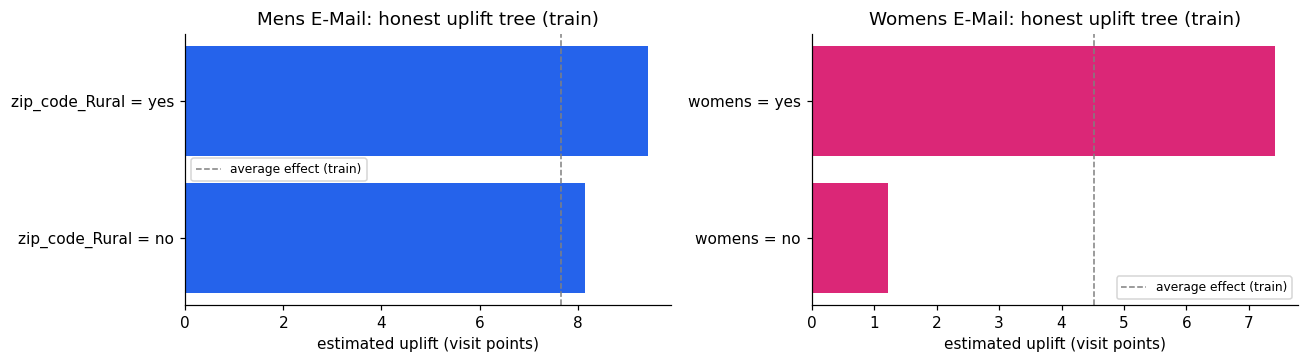

In [5]:
TREE_GRID = [dict(max_depth=d, min_leaf=ml, min_t=mt) for d in (2, 3) for ml in (500, 1000) for mt in (0.0, 2.0)]
tree_params, tree_tuning = select_tree_params(train, TREE_GRID)
display(tree_tuning.style.format({"qini_mens": "{:.4f}", "qini_womens": "{:.4f}"}))
print("Chosen per email:", {ARMS[a]: p for a, p in tree_params.items()})
u_tree = UpliftTreeLearner(params=tree_params).fit(X_tr, y_tr, a_tr)
tree_rules = u_tree.rules()
for email, rules in tree_rules.items():
    print(f"\n{email}: rules learned (uplift in visit points, n = customers in the estimation half)")
    display(rules.assign(uplift=lambda d: (d.uplift * 100).round(1)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, (email, rules), col in zip(axes, tree_rules.items(), ("#2563EB", "#DB2777")):
    r = rules.sort_values("uplift")
    ax.barh(r.rule, r.uplift * 100, color=col)
    ate_arm = train.loc[train.arm == ARM_CODES[email], "visit"].mean() - train.loc[train.arm == 0, "visit"].mean()
    ax.axvline(ate_arm * 100, ls="--", c="grey", lw=1, label="average effect (train)")
    ax.set_title(f"{email}: honest uplift tree (train)"); ax.set_xlabel("estimated uplift (visit points)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_uplift_tree.png", bbox_inches="tight"); plt.show()

## 4. Uplift-aware comparison of all models on the training set (5-fold cross-fitted Qini)
Each training customer is scored by models fitted on the other folds (encoder refitted per fold, same tuned parameters). The Qini coefficient (0 = random targeting; definition in `src/evaluation.py`) then measures *ranking* quality per email, using the training set only. This is how we pick the **deployment candidate** before touching the test set; the T-learner remains the pre-registered main model.

In [6]:
rng = np.random.default_rng(SEED)
cf = {"T-learner": cross_fit_uplift(train, lambda: TLearner(params=t_learner.params_)),
      "X-learner": cross_fit_uplift(train, lambda: XLearner(stage1=None), fit_kw={"tune": False}),
      "S-learner": cross_fit_uplift(train, lambda: SLearner(params=t_learner.params_[0])),
      "Uplift tree": cross_fit_uplift(train, lambda: UpliftTreeLearner(params=tree_params)),
      "Propensity": cross_fit_single(train, lambda: base_classifier(**t_learner.params_[0])),
      "Random": rng.random(len(train))}
train_qini = qini_per_email(train, cf)
display(train_qini.style.format("{:.4f}"))
deploy_candidate = {e: train_qini[e].drop(["Propensity", "Random"]).idxmax() for e in ("mens", "womens")}
print("Best uplift model per email on train (cross-fitted):", deploy_candidate)

email,mens,womens
model,,
T-learner,-0.0003,0.0017
X-learner,0.0006,0.0019
S-learner,0.0007,0.0025
Uplift tree,-0.0003,0.0036
Propensity,0.0025,0.0009
Random,-0.0006,-0.0001


Best uplift model per email on train (cross-fitted): {'mens': 'S-learner', 'womens': 'Uplift tree'}


## 5. Secondary model for the sensitivity check: T-learner on *conversion*
Conversion is rare (~0.9%), so we expect this model to be noisy. It is trained the same way, only to check in notebook 04 how much its ranking agrees with the visit-based ranking.

In [7]:
t_conv = TLearner().fit(X_tr, train["conversion"].to_numpy(), a_tr, tune=True)
for a, p in t_conv.params_.items():
    print(f"{ARMS[a]:14s} -> {p}")

No E-Mail      -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}
Mens E-Mail    -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
Womens E-Mail  -> {'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 200}


## 6. Which email would we send by default without a model?
Random and propensity targeting do not choose between emails, so they send the email with the **larger average effect on the training set**.

In [8]:
ate_train = {a: diff_in_means(train.loc[train.arm == a, "visit"], train.loc[train.arm == 0, "visit"])["diff"] for a in (1, 2)}
default_arm = max(ate_train, key=ate_train.get)
print({ARMS[a]: round(v, 4) for a, v in ate_train.items()}, "-> default email:", ARMS[default_arm])

{'Mens E-Mail': np.float64(0.0766), 'Womens E-Mail': np.float64(0.0452)} -> default email: Mens E-Mail


## 7. Score the held-out test set and save
One row per test customer (row index of the original data = customer ID): features, the arm they really got, the outcomes, and every model's scores. Notebook 04 and the dashboard read this file.

In [9]:
from src.models import recommend, model_inferred_segment

prop = joblib.load(MODELS_DIR / "propensity.joblib")["model"]

def score_customers(df, X):
    scores = df.copy()

    scores["propensity"] = prop.predict(X)
    scores["random_score"] = np.random.default_rng(SEED).random(len(df))

    out_T = t_learner.predict_outcomes(X)
    for c in out_T:
        scores[c] = out_T[c].to_numpy()

    for name, model in [
        ("T", t_learner),
        ("X", x_learner),
        ("S", s_learner),
        ("UT", u_tree),
        ("Tconv", t_conv),
    ]:
        u = model.predict_uplift(X)

        scores[f"{name}_uplift_mens"] = u["uplift_mens"].to_numpy()
        scores[f"{name}_uplift_womens"] = u["uplift_womens"].to_numpy()

        r = recommend(u)

        scores[f"{name}_policy_score"] = r["policy_score"].to_numpy()
        scores[f"{name}_best_arm"] = r["best_arm"].to_numpy()
        scores[f"{name}_action"] = r["recommended_action"].to_numpy()

    scores["default_arm"] = default_arm

    base_rate = float(train.loc[train.arm == 0, "visit"].mean())

    scores["T_segment"] = model_inferred_segment(
        scores["p_control"].to_numpy(),
        scores["T_policy_score"].to_numpy(),
        base_rate,
    )

    return scores


validation_scores = score_customers(validation, X_val)
test_scores = score_customers(test, X_te)

validation_scores.to_csv(PROCESSED_DIR / "validation_scores.csv")
test_scores.to_csv(PROCESSED_DIR / "test_scores.csv")

joblib.dump(
    {
        "T": t_learner,
        "X": x_learner,
        "S": s_learner,
        "UT": u_tree,
        "T_conversion": t_conv,
        "tree_params": tree_params,
    },
    MODELS_DIR / "uplift_models.joblib",
)

print("Validation customers scored:", len(validation_scores))
print("Testing customers scored:", len(test_scores))
print("Both score files saved successfully.")

display(
    validation_scores.filter(regex="uplift|policy|action").describe().T
)

Validation customers scored: 12800
Testing customers scored: 12800
Both score files saved successfully.


,count,mean,std,min,25%,50%,75%,max
T_uplift_mens,"12,800.0000",0.0756,0.0395,-0.1442,0.0530,0.0714,0.0979,0.2827
T_uplift_womens,"12,800.0000",0.0444,0.0457,-0.1289,0.0121,0.0403,0.0771,0.2628
T_policy_score,"12,800.0000",0.0834,0.0390,-0.1003,0.0587,0.0808,0.1059,0.2827
X_uplift_mens,"12,800.0000",0.0760,0.0189,0.0159,0.0625,0.0731,0.0873,0.1525
X_uplift_womens,"12,800.0000",0.0443,0.0296,-0.0251,0.0188,0.0456,0.0689,0.1225
X_policy_score,"12,800.0000",0.0787,0.0188,0.0159,0.0664,0.0773,0.0895,0.1525
S_uplift_mens,"12,800.0000",0.0651,0.0211,-0.0129,0.0493,0.0646,0.0777,0.1403
S_uplift_womens,"12,800.0000",0.0391,0.0295,-0.0434,0.0142,0.0417,0.0639,0.1599
S_policy_score,"12,800.0000",0.0681,0.0206,-0.0129,0.0533,0.0681,0.0807,0.1599
UT_uplift_mens,"12,800.0000",0.0834,0.0046,0.0815,0.0815,0.0815,0.0815,0.0943


## 8. What do the models recommend?
Counts of the recommended action (best email if its estimated uplift > 0, otherwise no email) and of the **model-inferred** targeting categories. These categories are predictions from the model, not facts about the customers; notebook 04 checks with held-out data whether, for example, "sleeping dogs" really react negatively.

In [11]:
scores = test_scores.copy()
actions = pd.DataFrame({m: scores[f"{m}_action"].value_counts(normalize=True) for m in ["T", "X", "S", "UT"]}).fillna(0)
display(actions)
seg = scores["T_segment"].value_counts(normalize=True)
display(seg.to_frame("share of test customers (T-learner, model-inferred)"))
print("Correlation of estimated uplift between learners (test set):")
display(scores[["T_uplift_mens", "X_uplift_mens", "S_uplift_mens", "UT_uplift_mens", "T_uplift_womens", "X_uplift_womens", "S_uplift_womens", "UT_uplift_womens"]].corr(method="spearman").round(2))

,T,X,S,UT
Mens E-Mail,0.6998,0.7982,0.7291,1.0000
No E-Mail,0.0140,0.0000,0.0002,0.0000
Womens E-Mail,0.2863,0.2018,0.2707,0.0000


,"share of test customers (T-learner, model-inferred)"
T_segment,
persuadable,0.9775
sure thing,0.0120
sleeping dog,0.0092
lost cause,0.0013


Correlation of estimated uplift between learners (test set):


,T_uplift_mens,X_uplift_mens,S_uplift_mens,UT_uplift_mens,T_uplift_womens,X_uplift_womens,S_uplift_womens,UT_uplift_womens
T_uplift_mens,1.0000,0.7200,0.6400,-0.1500,0.2900,0.2000,0.2100,0.0900
X_uplift_mens,0.7200,1.0000,0.6900,-0.1800,0.1700,0.1900,0.2200,0.1400
S_uplift_mens,0.6400,0.6900,1.0000,-0.1800,0.1000,0.0600,0.2000,0.0400
UT_uplift_mens,-0.1500,-0.1800,-0.1800,1.0000,-0.1000,-0.1100,-0.1200,-0.0100
T_uplift_womens,0.2900,0.1700,0.1000,-0.1000,1.0000,0.8200,0.7600,0.6900
X_uplift_womens,0.2000,0.1900,0.0600,-0.1100,0.8200,1.0000,0.8500,0.8500
S_uplift_womens,0.2100,0.2200,0.2000,-0.1200,0.7600,0.8500,1.0000,0.8500
UT_uplift_womens,0.0900,0.1400,0.0400,-0.0100,0.6900,0.8500,0.8500,1.0000


## 9. Who are the persuadables? (describing the T-learner)
Average estimated uplift by customer characteristic, on the training set. This describes what the model learned; it is not a causal claim about each feature.

mens


,uplift_mens,uplift_womens
mens,,
0,0.0727,0.0728
1,0.0782,0.0206


womens


,uplift_mens,uplift_womens
womens,,
0,0.0720,0.0116
1,0.0789,0.0706


newbie


,uplift_mens,uplift_womens
newbie,,
0,0.0828,0.0456
1,0.0689,0.0424


... (2 outputs left out)

zip_code


,uplift_mens,uplift_womens
zip_code,,
Rural,0.0595,0.0306
Surburban,0.0773,0.0481
Urban,0.0800,0.0444


recency_band


,uplift_mens,uplift_womens
recency_band,,
1-3,0.0819,0.0424
4-6,0.0822,0.0397
7-9,0.0651,0.0484
10-12,0.0697,0.0465


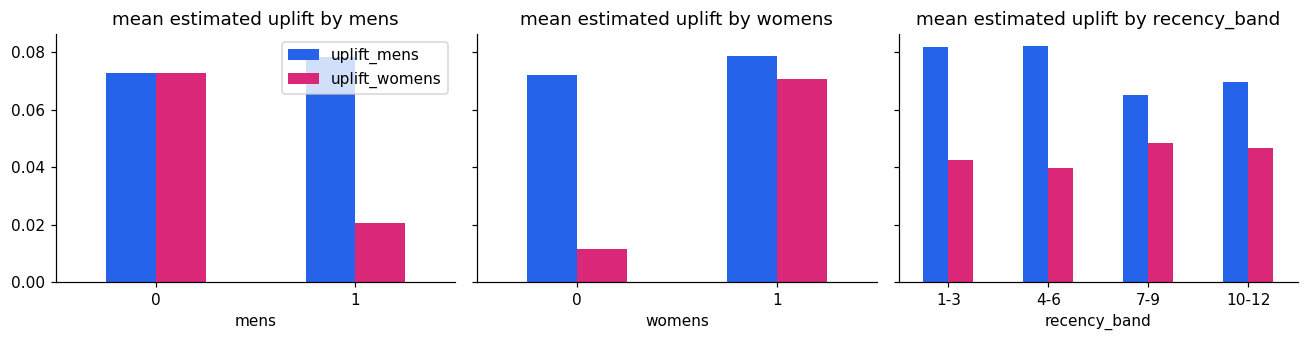

In [12]:
u_tr = t_learner.predict_uplift(X_tr)
desc = train.assign(**u_tr, recency_band=pd.cut(train.recency, [0, 3, 6, 9, 12], labels=["1-3", "4-6", "7-9", "10-12"]))
profiles = {}
for col in ["mens", "womens", "newbie", "channel", "zip_code", "recency_band"]:
    profiles[col] = desc.groupby(col, observed=True)[["uplift_mens", "uplift_womens"]].mean()
    print(col); display(profiles[col])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, col in zip(axes, ["mens", "womens", "recency_band"]):
    profiles[col].plot.bar(ax=ax, color=["#2563EB", "#DB2777"], rot=0, legend=(col == "mens"))
    ax.set_title(f"mean estimated uplift by {col}"); ax.set_xlabel(col)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_uplift_profiles.png", bbox_inches="tight"); plt.show()

In [14]:
base_rate = float(train.loc[train["arm"] == 0, "visit"].mean())
save_json({"T_params": {ARMS[a]: p for a, p in t_learner.params_.items()},
           "Tconv_params": {ARMS[a]: p for a, p in t_conv.params_.items()},
           "tree_params": {ARMS[a]: p for a, p in tree_params.items()}, "tree_tuning": tree_tuning.to_dict("records"),
           "tree_rules": {e: r.to_dict("records") for e, r in tree_rules.items()},
           "train_crossfit_qini": train_qini.reset_index().to_dict("records"),
           "deploy_candidate": deploy_candidate,
           "train_sanity_qini": {e: {"qini_T_oof": float(train_qini.loc["T-learner", e]), "qini_random": float(train_qini.loc["Random", e])} for e in ("mens", "womens")},
           "ate_train_visit": {ARMS[a]: v for a, v in ate_train.items()},
           "default_arm": ARMS[default_arm], "x_blend_g": {ARMS[a]: g for a, g in x_learner.g_.items()},
           "action_shares": actions.to_dict(), "segment_shares": seg.to_dict(), "base_rate_control": base_rate,
           "profiles": {k: v.reset_index().astype({v.index.name: str}).to_dict("records") for k, v in profiles.items()}},
          "03_models.json")
print("saved")

saved


## What we found

- **T-Learner:** Our main uplift model estimates how much each email changes a customer's probability of visiting.
- **Honest uplift tree:** The tree identifies interpretable customer groups with different estimated responses to the emails. For the women's email, customers with previous women's-merchandise purchases show a stronger estimated response.
- **Uplift-aware model comparison (5-fold cross-fitted Qini on training):**
  - **Men's email:** S-Learner (0.0007), X-Learner (0.0006), T-Learner (-0.0003), Uplift Tree (-0.0003). The propensity baseline (0.0025) outperforms all four uplift models.
  - **Women's email:** Uplift Tree (0.0036), S-Learner (0.0025), X-Learner (0.0019), T-Learner (0.0017), compared with propensity (0.0009).
- **Model selection:** Among uplift models, the S-Learner ranks highest for men's email and the Uplift Tree ranks highest for women's email on the training cross-validation results. These rankings do not guarantee better performance on unseen customers.
- **Default email without personalization:** Men's email, because its average training-set effect is approximately +7.7 percentage points, compared with +4.5 points for women's email.
- **Evaluation strategy:** Models are trained on 38,400 customers. The separate validation set (12,800) is used for decisions such as targeting thresholds, while the untouched test set (12,800) is reserved for final evaluation.
- **Next step:** Notebook 04 will assess whether uplift targeting actually improves campaign performance compared with propensity-based and random targeting, including uncertainty and financial outcomes.